In [1]:
import pandas as pd
url = 'https://raw.githubusercontent.com/rashakil-ds/Public-Datasets/refs/heads/main/airquality.csv'
df = pd.read_csv(url)
df.head()

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,2004-03-10,18:00:00,2.6,1360,150,11.9,1046,166,1056,113,1692,1268,13.6,48.9,0.7578
1,2004-03-10,19:00:00,2.0,1292,112,9.4,955,103,1174,92,1559,972,13.3,47.7,0.7255
2,2004-03-10,20:00:00,2.2,1402,88,9.0,939,131,1140,114,1555,1074,11.9,54.0,0.7502
3,2004-03-10,21:00:00,2.2,1376,80,9.2,948,172,1092,122,1584,1203,11.0,60.0,0.7867
4,2004-03-10,22:00:00,1.6,1272,51,6.5,836,131,1205,116,1490,1110,11.2,59.6,0.7888


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


In [3]:
TARGETS = ["CO(GT)", "NO2(GT)"]
ENV = ["T", "RH", "AH"]
ENV_LAGS = [1, 24]

In [4]:
data = df.copy()

In [5]:
data["datetime"] = pd.to_datetime(data["Date"]+" "+data["Time"])

In [6]:
data = data.set_index("datetime").sort_index()

In [7]:
data = data.drop(columns=["Date","Time"])

In [8]:
data = data.replace(-200,np.nan)
data

,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
datetime,,,,,,,,,,,,,
2004-03-10 18:00:00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
2004-03-10 19:00:00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2004-03-10 20:00:00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
2004-03-10 21:00:00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
2004-03-10 22:00:00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2005-04-04 10:00:00,3.1,1314.0,NaN,13.5,1101.0,472.0,539.0,190.0,1374.0,1729.0,21.9,29.3,0.7568
2005-04-04 11:00:00,2.4,1163.0,NaN,11.4,1027.0,353.0,604.0,179.0,1264.0,1269.0,24.3,23.7,0.7119
2005-04-04 12:00:00,2.4,1142.0,NaN,12.4,1063.0,293.0,603.0,175.0,1241.0,1092.0,26.9,18.3,0.6406


In [9]:
data = data[~data.index.duplicated()].asfreq(freq="h")
data

,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
datetime,,,,,,,,,,,,,
2004-03-10 18:00:00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
2004-03-10 19:00:00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2004-03-10 20:00:00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
2004-03-10 21:00:00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
2004-03-10 22:00:00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2005-04-04 10:00:00,3.1,1314.0,NaN,13.5,1101.0,472.0,539.0,190.0,1374.0,1729.0,21.9,29.3,0.7568
2005-04-04 11:00:00,2.4,1163.0,NaN,11.4,1027.0,353.0,604.0,179.0,1264.0,1269.0,24.3,23.7,0.7119
2005-04-04 12:00:00,2.4,1142.0,NaN,12.4,1063.0,293.0,603.0,175.0,1241.0,1092.0,26.9,18.3,0.6406


In [10]:
data = data.loc[:,data.isna().mean()<0.9]
data.shape

(9357, 12)

In [11]:
def impute_series(s, lim=6):
    s = s.copy()
    fill = s.interpolate(method="time", limit=lim, limit_area="inside")
    idx = fill.index
    profilemdh = s.groupby([idx.month, idx.dayofweek, idx.hour]).transform("median")
    profiledh = s.groupby([idx.dayofweek, idx.hour]).transform("median")
    fill = fill.fillna(profilemdh).fillna(profiledh)
    # print(len(fill))
    return fill.interpolate(method="time").bfill().ffill()


In [12]:
cols = TARGETS + ENV + ["NOx(GT)","C6H6(GT)"]
raw = data[cols].copy()
data = data[cols].apply(impute_series, lim=6)

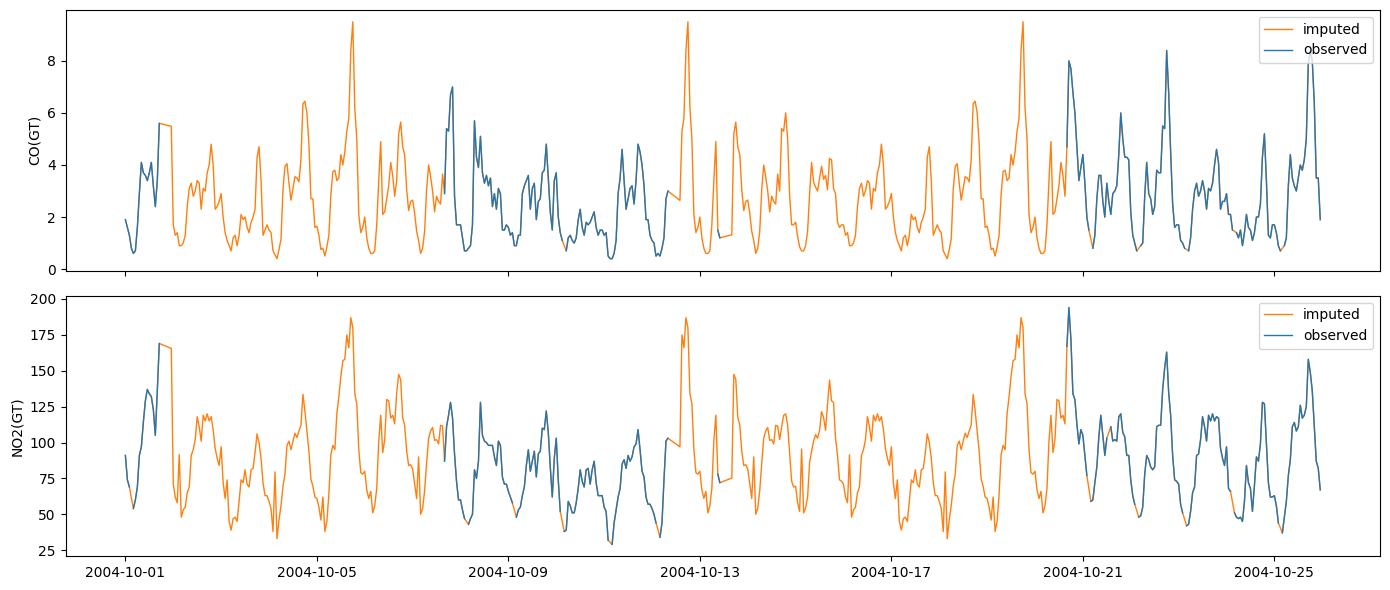

In [13]:
idx = slice("2004-10-01", "2004-10-25")
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
for ax, c in zip(axes, TARGETS):
    ax.plot(data.loc[idx, c], color="tab:orange", lw=1, label="imputed")
    ax.plot(raw.loc[idx, c], color="tab:blue", lw=1, label="observed")
    ax.set_ylabel(c); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

In [14]:
dfh = data.copy()
dfd = data.resample("D").mean()

In [15]:
dfd.shape

(391, 7)

In [16]:
dfh[TARGETS + ENV].describe().round(2)

,CO(GT),NO2(GT),T,RH,AH
count,9357.00,9357.00,9357.00,9357.00,9357.00
mean,2.12,108.81,18.20,49.20,1.02
std,1.45,47.48,8.87,17.18,0.41
min,0.10,2.00,-1.90,9.20,0.18
25%,1.00,73.00,11.50,35.90,0.72
50%,1.80,104.00,17.60,49.60,0.99
75%,2.80,137.00,24.40,62.20,1.31
max,11.90,340.00,44.60,88.70,2.23


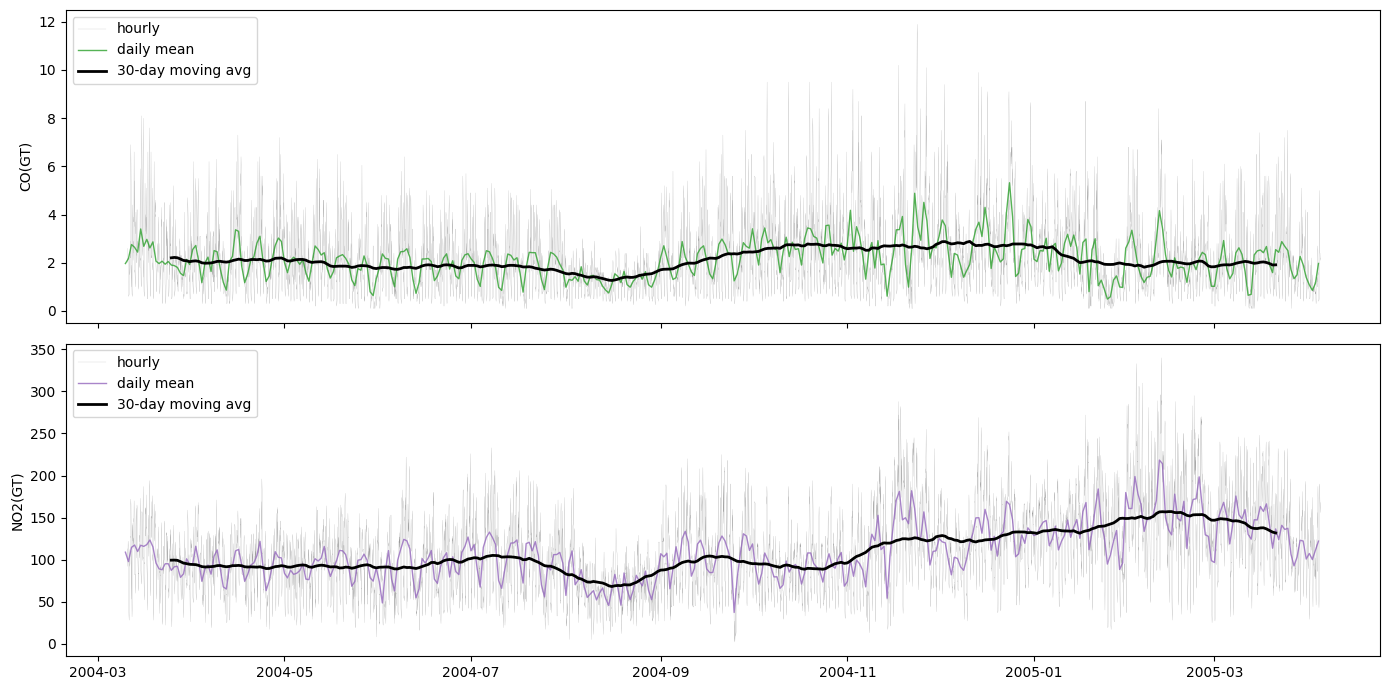

datetime,2004-03,2004-04,2004-05,2004-06,2004-07,2004-08,2004-09,2004-10,2004-11,2004-12,2005-01,2005-02,2005-03,2005-04
CO(GT),2.25,2.15,1.85,1.90,1.87,1.28,2.15,2.72,2.71,2.78,2.02,2.08,2.00,1.19
NO2(GT),101.05,93.14,91.28,93.08,102.15,68.55,103.91,90.13,121.06,123.76,132.98,158.45,136.52,108.93


In [17]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for ax, c, col in zip(axes, TARGETS, ["tab:green", "tab:purple"]):
    ax.plot(dfh[c], color="gray", lw=0.1, label="hourly")
    ax.plot(dfd[c], color=col, lw=1, alpha=0.8, label="daily mean")
    ax.plot(dfd[c].rolling(30, center=True).mean(), color="black", lw=2, label="30-day moving avg")
    ax.set_ylabel(c); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

monthly = dfh[TARGETS].resample("MS").mean()  #ms = month start
monthly.index = monthly.index.strftime("%Y-%m")
monthly.round(2).T

In [20]:
pip install statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 32.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.9/118.9 kB 11.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 233.3/233.3 kB 19.0 MB/s eta 0:00:00


In [21]:
from statsmodels.graphics.tsaplots import plot_acf
tmp = dfh[TARGETS].copy()
tmp

,CO(GT),NO2(GT)
datetime,,
2004-03-10 18:00:00,2.6,113.0
2004-03-10 19:00:00,2.0,92.0
2004-03-10 20:00:00,2.2,114.0
2004-03-10 21:00:00,2.2,122.0
2004-03-10 22:00:00,1.6,116.0
...,...,...
2005-04-04 10:00:00,3.1,190.0
2005-04-04 11:00:00,2.4,179.0
2005-04-04 12:00:00,2.4,175.0


In [22]:
tmp["hour"] = tmp.index.hour
tmp["dow"] = tmp.index.dayofweek
tmp["month"] = tmp.index.month
tmp["day_type"] = np.where(tmp["dow"] >= 5, "Weekend", "Weekday")
dow_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
tmp

,CO(GT),NO2(GT),hour,dow,month,day_type
datetime,,,,,,
2004-03-10 18:00:00,2.6,113.0,18,2,3,Weekday
2004-03-10 19:00:00,2.0,92.0,19,2,3,Weekday
2004-03-10 20:00:00,2.2,114.0,20,2,3,Weekday
2004-03-10 21:00:00,2.2,122.0,21,2,3,Weekday
2004-03-10 22:00:00,1.6,116.0,22,2,3,Weekday
...,...,...,...,...,...,...
2005-04-04 10:00:00,3.1,190.0,10,0,4,Weekday
2005-04-04 11:00:00,2.4,179.0,11,0,4,Weekday
2005-04-04 12:00:00,2.4,175.0,12,0,4,Weekday


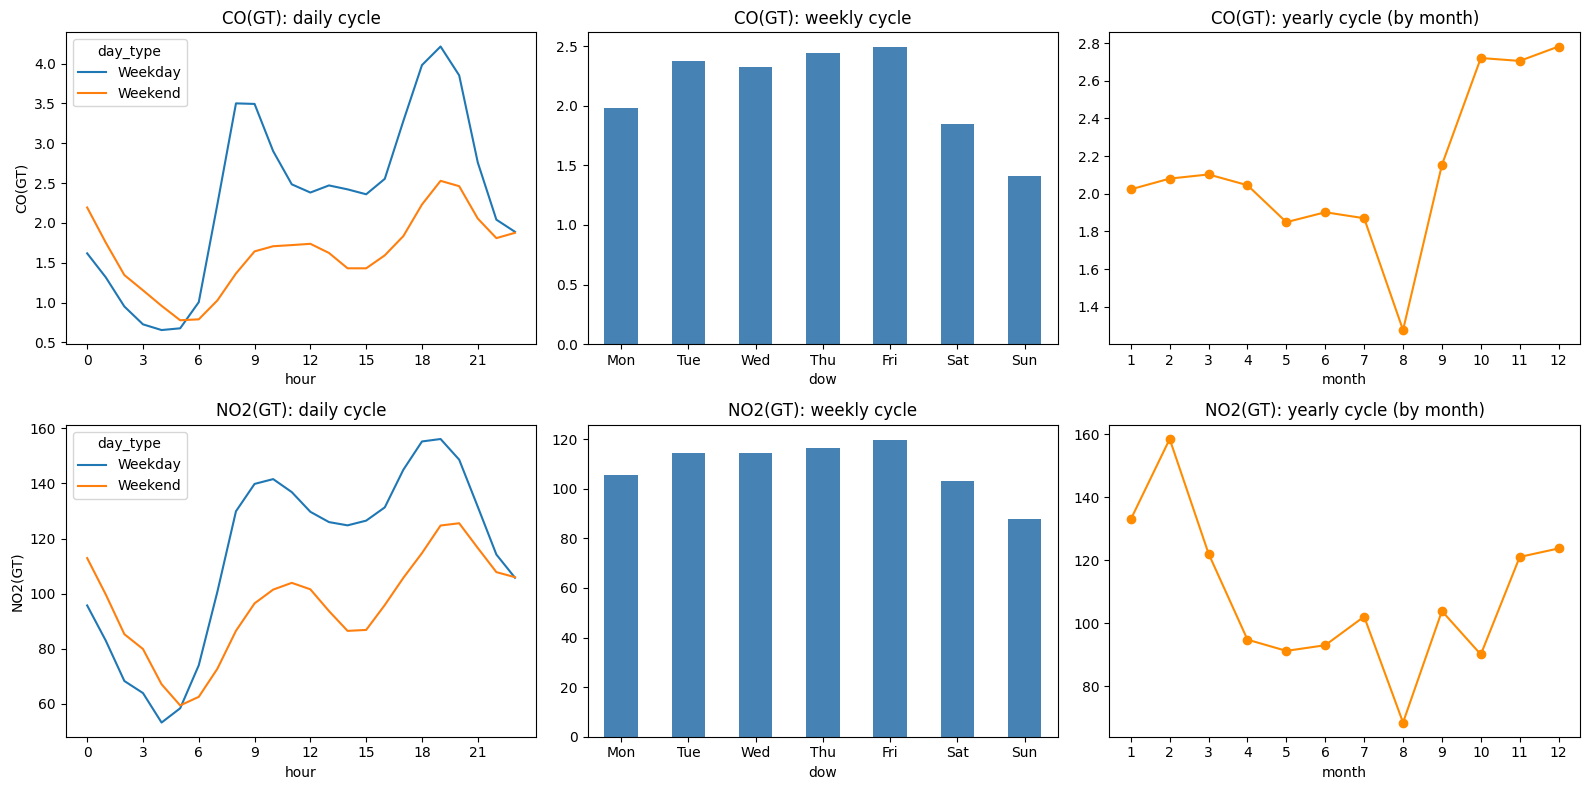

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for r, c in enumerate(TARGETS):
    sns.lineplot(data=tmp, x="hour", y=c, hue="day_type", ax=axes[r, 0], errorbar=None)
    axes[r, 0].set_title(f"{c}: daily cycle"); axes[r, 0].set_xticks(range(0, 24, 3))
    tmp.groupby("dow")[c].mean().plot.bar(ax=axes[r, 1], color="steelblue")
    axes[r, 1].set_xticklabels(dow_names, rotation=0); axes[r, 1].set_title(f"{c}: weekly cycle")
    tmp.groupby("month")[c].mean().plot(ax=axes[r, 2], marker="o", color="darkorange")
    axes[r, 2].set_title(f"{c}: yearly cycle (by month)"); axes[r, 2].set_xticks(range(1, 13))
plt.tight_layout(); plt.show()

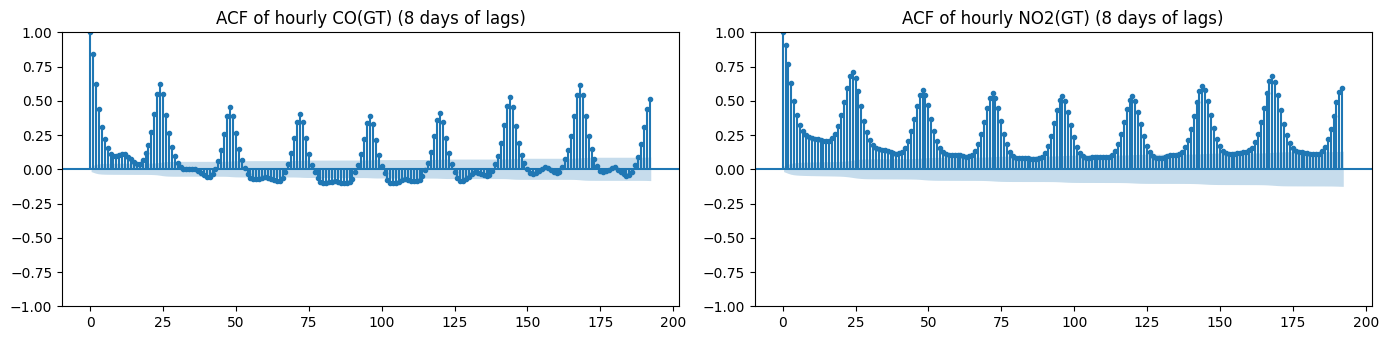

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
for ax, c in zip(axes, TARGETS):
    plot_acf(dfh[c], lags=24 * 8, ax=ax, markersize=3)
    ax.set_title(f"ACF of hourly {c} (8 days of lags)")
plt.tight_layout(); plt.show()

In [25]:
corr_cols = TARGETS + ["NOx(GT)", "C6H6(GT)"] + ENV
corr = dfh[corr_cols].corr()


print(corr.loc[TARGETS, ENV + ["NOx(GT)", "C6H6(GT)"]].round(2))

            T    RH    AH  NOx(GT)  C6H6(GT)
CO(GT)   0.02  0.01  0.01     0.80      0.87
NO2(GT) -0.20 -0.12 -0.35     0.76      0.59


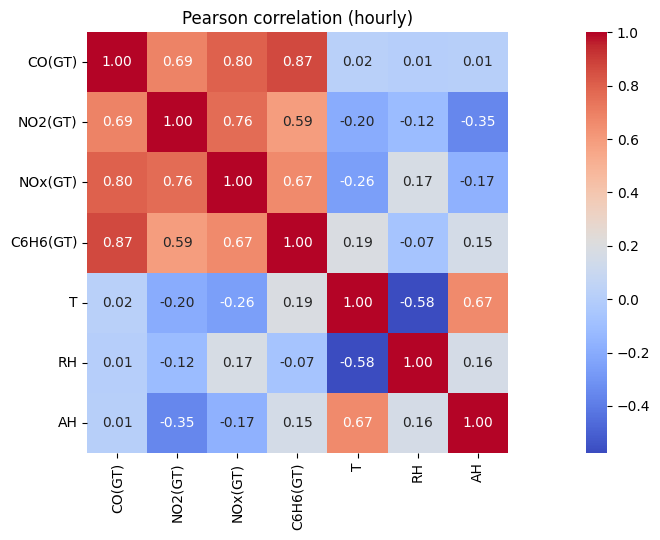

In [26]:
fig, ax = plt.subplots(1, 1, figsize=(16, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", square=True)
ax.set_title("Pearson correlation (hourly)")
plt.tight_layout(); plt.show()

In [27]:
def time_features(dframe):
    out = dframe.copy()
    idx = out.index
    out["month"] = idx.month
    out["hour"] = idx.hour
    out["dayofweek"] = idx.dayofweek
    out["is_weekend"] = (idx.dayofweek >= 5).astype(int)
    out["hour_sin"] = np.sin(2 * np.pi * idx.hour / 24)
    out["hour_cos"] = np.cos(2 * np.pi * idx.hour / 24)
    out["dow_sin"] = np.sin(2 * np.pi * idx.dayofweek / 7)
    out["dow_cos"] = np.cos(2 * np.pi * idx.dayofweek / 7)
    out["month_sin"] = np.sin(2 * np.pi * (idx.month - 1) / 12)
    out["month_cos"] = np.cos(2 * np.pi * (idx.month - 1) / 12)
    return out

basedf = time_features(dfh[TARGETS + ENV])
basedf.head()

,CO(GT),NO2(GT),T,RH,AH,month,hour,dayofweek,is_weekend,hour_sin,hour_cos,dow_sin,dow_cos,month_sin,month_cos
datetime,,,,,,,,,,,,,,,
2004-03-10 18:00:00,2.6,113.0,13.6,48.9,0.7578,3,18,2,0,-1.000000,-1.836970e-16,0.974928,-0.222521,0.866025,0.5
2004-03-10 19:00:00,2.0,92.0,13.3,47.7,0.7255,3,19,2,0,-0.965926,2.588190e-01,0.974928,-0.222521,0.866025,0.5
2004-03-10 20:00:00,2.2,114.0,11.9,54.0,0.7502,3,20,2,0,-0.866025,5.000000e-01,0.974928,-0.222521,0.866025,0.5
2004-03-10 21:00:00,2.2,122.0,11.0,60.0,0.7867,3,21,2,0,-0.707107,7.071068e-01,0.974928,-0.222521,0.866025,0.5
2004-03-10 22:00:00,1.6,116.0,11.2,59.6,0.7888,3,22,2,0,-0.500000,8.660254e-01,0.974928,-0.222521,0.866025,0.5


In [28]:
LAGS = [1, 2, 3, 6, 12, 24, 48, 168]   # 1 h ... 1 week
TIME_FEATS = ["hour_sin", "hour_cos", "dow_sin", "dow_cos", "month_sin", "month_cos", "is_weekend"]

In [29]:
def build_features(frame, target):
    X = frame[TIME_FEATS].copy()
    y = frame[target]
    for lag in LAGS:
        X[f"{target}_lag{lag}"] = y.shift(lag)
    # Rolling statistics use only past values (shift(1) avoids leakage)
    past = y.shift(1)
    X[f"{target}_roll3_mean"] = past.rolling(3).mean()
    X[f"{target}_roll24_mean"] = past.rolling(24).mean()
    X[f"{target}_roll24_std"] = past.rolling(24).std()
    other = [t for t in TARGETS if t != target][0]
    X[f"{other}_lag1"] = frame[other].shift(1)
    for e in ENV:
        for lag in ENV_LAGS:
            X[f"{e}_lag{lag}"] = frame[e].shift(lag)
    valid = X.notna().all(axis=1)
    return X[valid], y[valid]


In [30]:
features = {t: build_features(basedf, t) for t in TARGETS}

In [31]:
for t, (X, y) in features.items():
    print(f"{t}: X shape = {X.shape}")

CO(GT): X shape = (9189, 25)
NO2(GT): X shape = (9189, 25)


In [33]:
len(dfh)*0.8

7485.6

In [32]:
pos = int(len(dfh) * (0.8))
split_time = dfh.index[pos]
print("Train:", dfh.index.min(), "to ", dfh.index[pos - 1])
print("Test :", split_time, "to ", dfh.index.max())

Train: 2004-03-10 18:00:00 to  2005-01-16 14:00:00
Test : 2005-01-16 15:00:00 to  2005-04-04 14:00:00


In [34]:
splits = {}
for t, (X, y) in features.items():
    tr, te = X.index < split_time, X.index >= split_time
    splits[t] = dict(X_train=X[tr], X_test=X[te], y_train=y[tr], y_test=y[te])
    print(f"{t}: train={tr.sum()}, test={te.sum()}")

predictions = {t: pd.DataFrame({"actual": splits[t]["y_test"]}) for t in TARGETS}

CO(GT): train=7317, test=1872
NO2(GT): train=7317, test=1872


In [35]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

In [36]:
predictions[TARGETS[0]]

,actual
datetime,
2005-01-16 15:00:00,0.7
2005-01-16 16:00:00,1.1
2005-01-16 17:00:00,1.1
2005-01-16 18:00:00,1.2
2005-01-16 19:00:00,2.0
...,...
2005-04-04 10:00:00,3.1
2005-04-04 11:00:00,2.4
2005-04-04 12:00:00,2.4


In [37]:
for t in TARGETS:
    p = predictions[t]
    p["Persistence (t-1)"] = dfh[t].shift(1).loc[p.index]
    p["Seasonal naive (t-24)"] = dfh[t].shift(24).loc[p.index]


class SARIMAEstimator(BaseEstimator, RegressorMixin):
  # for hyperparameter tuning
    def __init__(self, order=(1, 0, 1), seasonal_order=(1, 1, 1, 24), maxiter=50):
        self.order = order
        self.seasonal_order = seasonal_order
        self.maxiter = maxiter

    def fit(self, X, y):
        y = np.asarray(y, dtype=float)
        self.res_ = SARIMAX(y, order=self.order, seasonal_order=self.seasonal_order,
                            enforce_stationarity=False, enforce_invertibility=False
                            ).fit(disp=False, maxiter=self.maxiter)
        self.n_train_ = len(y)
        return self

    def one_step(self, y):
        y = np.asarray(y, dtype=float)
        res = self.res_.append(y, refit=False)
        return res.predict(start=self.n_train_, end=self.n_train_ + len(y) - 1)

    def predict(self, X):  # multi-step forecast (used only if someone calls predict directly)
        return self.res_.forecast(steps=len(X))

    def score(self, X, y):
        pred = self.one_step(y)
        return -np.sqrt(np.mean((np.asarray(y) - pred) ** 2))



In [38]:
sarima_grid = {
    "order": [(1, 0, 0), (1, 0, 1), (2, 0, 1)],
    "seasonal_order": [(0, 1, 1, 24), (1, 1, 1, 24)],
}
sarima_cv = TimeSeriesSplit(n_splits=3, test_size=24*7)   # three consecutive 1-week validation folds

sarima_search, sarima_results = {}, {}
for t in TARGETS:
    y_all = dfh[t]
    y_tr = y_all[y_all.index < split_time].iloc[-(24*120):]
    y_te = y_all[y_all.index >= split_time]
    gs = GridSearchCV(SARIMAEstimator(), sarima_grid, cv=sarima_cv, n_jobs=-1, refit=False)
    gs.fit(np.arange(len(y_tr)).reshape(-1, 1), y_tr.values)
    sarima_search[t] = gs
    best = gs.best_params_
    print(f"CV RMSE = {-gs.best_score_:.3f}")

    # Refit the best configuration on the full 120-day window (with the datetime index, for forecasting)
    res = SARIMAX(y_tr, order=best["order"], seasonal_order=best["seasonal_order"],
                  enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=200)
    res_test = res.append(y_te, refit=False)          # extend the state through the test period
    one_step = res_test.predict(start=y_te.index[0], end=y_te.index[-1])
    predictions[t]["SARIMA"] = one_step.loc[predictions[t].index]
    sarima_results[t] = res_test

CV RMSE = 0.582
CV RMSE = 12.848


In [39]:
sarima_cv_table = pd.concat({
    t: pd.DataFrame({"order": [str(p["order"]) for p in g.cv_results_["params"]],
                     "seasonal_order": [str(p["seasonal_order"]) for p in g.cv_results_["params"]],
                     "CV RMSE": -g.cv_results_["mean_test_score"],
                     "rank": g.cv_results_["rank_test_score"]})
    for t, g in sarima_search.items()})
print()
print(sarima_results["CO(GT)"].summary().tables[1])
sarima_cv_table.round(3)


                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3950      0.094      4.201      0.000       0.211       0.579
ar.L2          0.3387      0.082      4.109      0.000       0.177       0.500
ma.L1          0.5426      0.089      6.072      0.000       0.367       0.718
ma.S.L24      -0.9173      0.007   -137.637      0.000      -0.930      -0.904
sigma2         0.5053      0.008     60.682      0.000       0.489       0.522


order seasonal_order  CV RMSE  rank
CO(GT)  0  (1, 0, 0)  (0, 1, 1, 24)    0.583     2
        1  (1, 0, 0)  (1, 1, 1, 24)    0.585     5
        2  (1, 0, 1)  (0, 1, 1, 24)    0.584     4
        3  (1, 0, 1)  (1, 1, 1, 24)    0.585     6
        4  (2, 0, 1)  (0, 1, 1, 24)    0.582     1
        5  (2, 0, 1)  (1, 1, 1, 24)    0.583     3
NO2(GT) 0  (1, 0, 0)  (0, 1, 1, 24)   12.914     6
        1  (1, 0, 0)  (1, 1, 1, 24)   12.904     5
        2  (1, 0, 1)  (0, 1, 1, 24)   12.857     2
        3  (1, 0, 1)  (1, 1, 1, 24)   12.848     1
        4  (2, 0, 1)  (0, 1, 1, 24)   12.875     4
        5  (2, 0, 1)  (1, 1, 1, 24)   12.857     3

In [40]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler

In [41]:
ridge_pipe = Pipeline([("scaler", StandardScaler()), ("ridge", Ridge())])
ridge_grid = {"scaler": [StandardScaler(), RobustScaler()], "ridge__alpha": np.logspace(-3, 3, 13)}
ridge_cv = TimeSeriesSplit(n_splits=5)

In [42]:
ridge_cv

TimeSeriesSplit(gap=0, max_train_size=None, n_splits=5, test_size=None)

In [44]:
ridge_search = {}
for t in TARGETS:
    s = splits[t]
    gs = GridSearchCV(ridge_pipe, ridge_grid, cv=ridge_cv, scoring="neg_root_mean_squared_error", n_jobs=-1, refit=True)
    gs.fit(s["X_train"], s["y_train"])            # refit=True: retrains the best pipeline on all training data
    ridge_search[t] = gs
    predictions[t]["Ridge regression"] = gs.predict(s["X_test"])
    bp = gs.best_params_
    print(f"CV RMSE = {-gs.best_score_:.3f}")

CV RMSE = 0.657
CV RMSE = 16.629


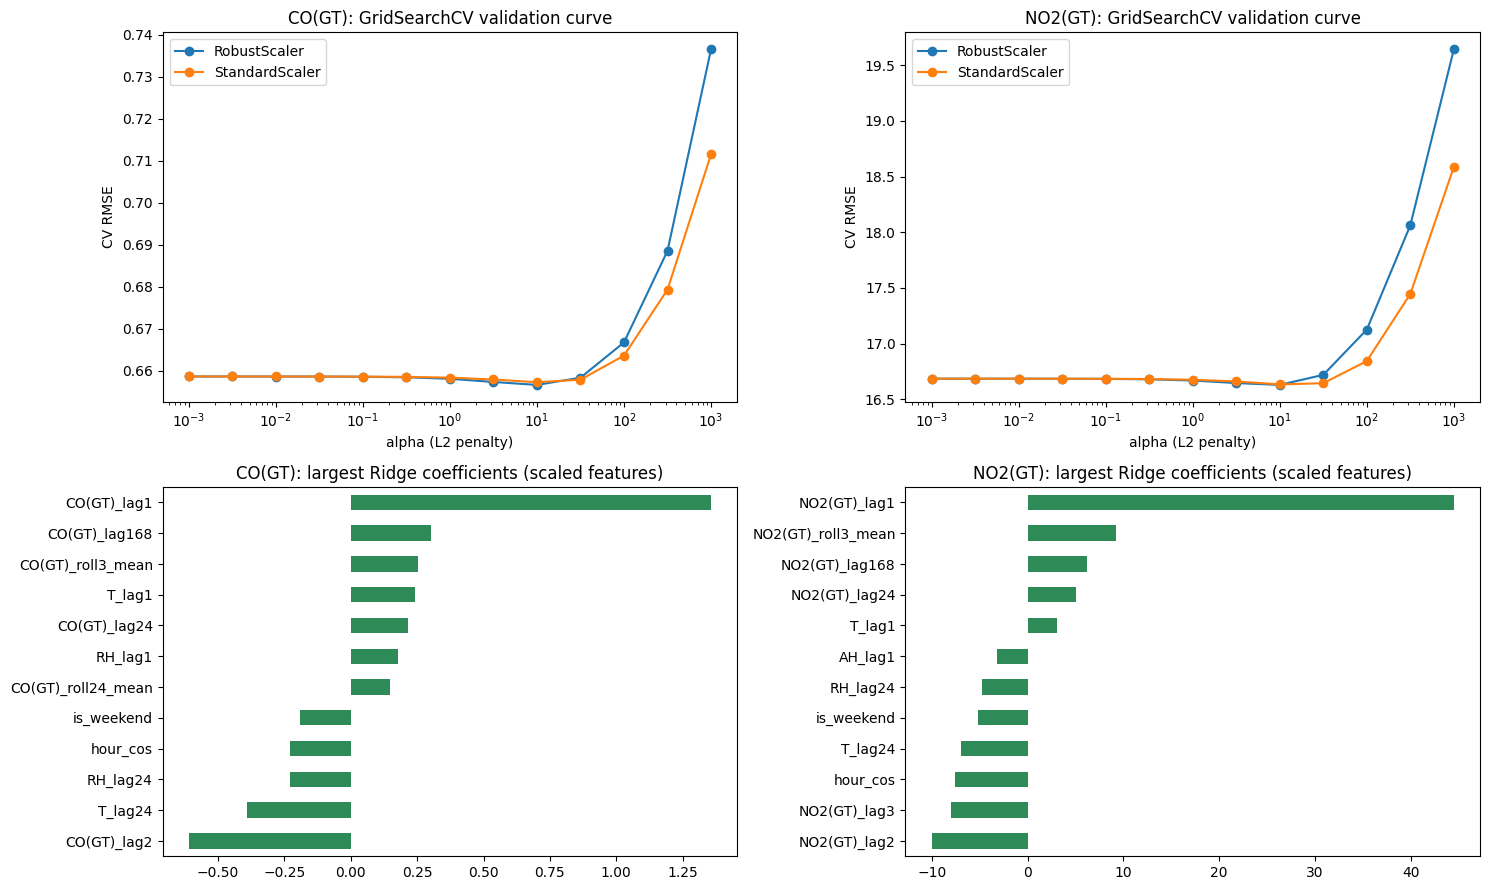

In [45]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for c, t in enumerate(TARGETS):
    cvr = pd.DataFrame(ridge_search[t].cv_results_)
    cvr["scaler_name"] = cvr["param_scaler"].map(lambda s: type(s).__name__)
    for name, g in cvr.groupby("scaler_name"):
        axes[0, c].plot(g["param_ridge__alpha"].astype(float), -g["mean_test_score"], marker="o", label=name)
    axes[0, c].set_xscale("log"); axes[0, c].set_xlabel("alpha (L2 penalty)"); axes[0, c].set_ylabel("CV RMSE")
    axes[0, c].set_title(f"{t}: GridSearchCV validation curve"); axes[0, c].legend()

    best = ridge_search[t].best_estimator_
    coef = pd.Series(best.named_steps["ridge"].coef_, index=splits[t]["X_train"].columns)
    coef.reindex(coef.abs().nlargest(12).index).sort_values().plot.barh(ax=axes[1, c], color="seagreen")
    axes[1, c].set_title(f"{t}: largest Ridge coefficients (scaled features)")
plt.tight_layout(); plt.show()

In [46]:
%pip install tensorflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.9/572.9 MB 855.4 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.5/57.5 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 45.5 MB/s eta 0:00:00


In [47]:
import tensorflow as tf
from tensorflow import keras
from sklearn.preprocessing import MinMaxScaler
tf.get_logger().setLevel("ERROR")
keras.utils.set_random_seed(RANDOM_STATE)
tf.config.experimental.enable_op_determinism()   # reproducible training runs

/usr/local/lib/python3.13/dist-packages/jax/_src/cloud_tpu_init.py:90: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(


In [48]:
WINDOW = 24
SEQ_FEATS = TIME_FEATS + ENV

In [49]:
def make_seq(frame, target):
    cols = [target] + [c for c in TARGETS if c != target] + SEQ_FEATS
    train_mask = frame.index < split_time
    scaler_X = MinMaxScaler().fit(frame.loc[train_mask, cols])     # scalers fitted on training data only
    scaler_y = MinMaxScaler().fit(frame.loc[train_mask, [target]])
    Xs = scaler_X.transform(frame[cols])
    ys = scaler_y.transform(frame[[target]]).ravel()
    X, y, idx = [], [], []
    for i in range(WINDOW, len(frame)):
        X.append(Xs[i - WINDOW:i]); y.append(ys[i]); idx.append(frame.index[i])   # window ends at t-1
    return np.array(X, dtype="float32"), np.array(y, dtype="float32"), pd.DatetimeIndex(idx), scaler_X, scaler_y

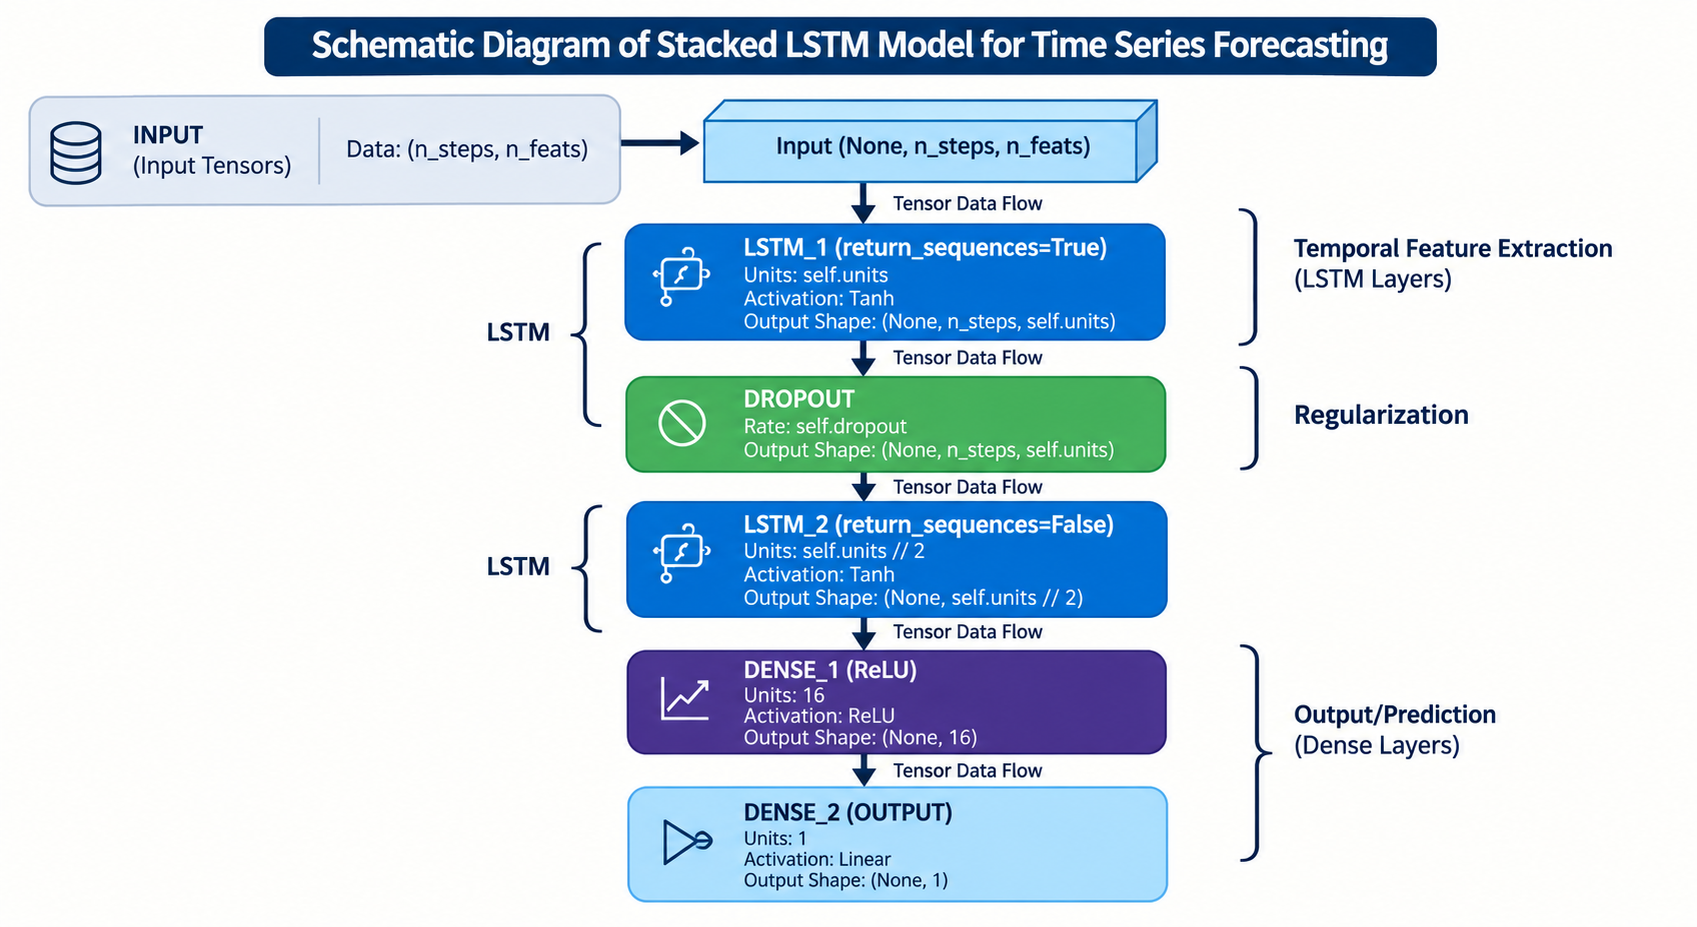

In [50]:
class LSTMRegressor(BaseEstimator, RegressorMixin):
    def __init__(self, units=64, dropout=0.2, learning_rate=1e-3, epochs=30, batch_size=128,
                 patience=4, random_state=42):
        self.units = units
        self.dropout = dropout
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        self.patience = patience
        self.random_state = random_state

    def _build(self, n_steps, n_feats):
        model = keras.Sequential([
            keras.layers.Input(shape=(n_steps, n_feats)),
            keras.layers.LSTM(self.units, return_sequences=True),
            keras.layers.Dropout(self.dropout),
            keras.layers.LSTM(self.units // 2),
            keras.layers.Dense(16, activation="relu"),
            keras.layers.Dense(1),
        ])
        model.compile(optimizer=keras.optimizers.Adam(self.learning_rate), loss="mse")
        return model

    def fit(self, X, y):
        keras.backend.clear_session()
        keras.utils.set_random_seed(self.random_state)
        self.model_ = self._build(X.shape[1], X.shape[2])
        cb = [keras.callbacks.EarlyStopping(patience=self.patience, restore_best_weights=True),
              keras.callbacks.ReduceLROnPlateau(patience=2, factor=0.5)]
        # validation_split takes the LAST 10% of the (chronological) training fold for early stopping
        h = self.model_.fit(X, y, validation_split=0.1, epochs=self.epochs, batch_size=self.batch_size,
                            callbacks=cb, verbose=0, shuffle=True)
        self.history_ = h.history
        return self

    def predict(self, X):
        return self.model_.predict(X, verbose=0, batch_size=1024).ravel()

In [51]:
lstm_grid = {
    "units": [32, 64],
    "dropout": [0.1, 0.3],
    "learning_rate": [1e-3, 3e-3],
}
lstm_cv = TimeSeriesSplit(n_splits=3)

In [52]:
basedf

,CO(GT),NO2(GT),T,RH,AH,month,hour,dayofweek,is_weekend,hour_sin,hour_cos,dow_sin,dow_cos,month_sin,month_cos
datetime,,,,,,,,,,,,,,,
2004-03-10 18:00:00,2.6,113.0,13.6,48.9,0.7578,3,18,2,0,-1.000000e+00,-1.836970e-16,0.974928,-0.222521,0.866025,5.000000e-01
2004-03-10 19:00:00,2.0,92.0,13.3,47.7,0.7255,3,19,2,0,-9.659258e-01,2.588190e-01,0.974928,-0.222521,0.866025,5.000000e-01
2004-03-10 20:00:00,2.2,114.0,11.9,54.0,0.7502,3,20,2,0,-8.660254e-01,5.000000e-01,0.974928,-0.222521,0.866025,5.000000e-01
2004-03-10 21:00:00,2.2,122.0,11.0,60.0,0.7867,3,21,2,0,-7.071068e-01,7.071068e-01,0.974928,-0.222521,0.866025,5.000000e-01
2004-03-10 22:00:00,1.6,116.0,11.2,59.6,0.7888,3,22,2,0,-5.000000e-01,8.660254e-01,0.974928,-0.222521,0.866025,5.000000e-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2005-04-04 10:00:00,3.1,190.0,21.9,29.3,0.7568,4,10,0,0,5.000000e-01,-8.660254e-01,0.000000,1.000000,1.000000,6.123234e-17
2005-04-04 11:00:00,2.4,179.0,24.3,23.7,0.7119,4,11,0,0,2.588190e-01,-9.659258e-01,0.000000,1.000000,1.000000,6.123234e-17
2005-04-04 12:00:00,2.4,175.0,26.9,18.3,0.6406,4,12,0,0,1.224647e-16,-1.000000e+00,0.000000,1.000000,1.000000,6.123234e-17


In [53]:
lstm_search, lstm_scalers = {}, {}
for t in TARGETS:
    X, y, idx, sx, sy = make_seq(basedf, t)
    tr, te = idx < split_time, idx >= split_time
    gs = GridSearchCV(LSTMRegressor(), lstm_grid, cv=lstm_cv, scoring="neg_root_mean_squared_error", n_jobs=1, refit=True)   # n_jobs=1: Keras is not fork-safe
    gs.fit(X[tr], y[tr])
    lstm_search[t], lstm_scalers[t] = gs, sy
    pred = sy.inverse_transform(gs.predict(X[te]).reshape(-1, 1)).ravel()
    predictions[t]["LSTM"] = pd.Series(pred, index=idx[te]).loc[predictions[t].index]
    hist = gs.best_estimator_.history_
    print(f"CV RMSE (scaled) = {-gs.best_score_:.3f}; final model: {len(hist['loss'])} epochs")


CV RMSE (scaled) = 0.089; final model: 20 epochs
CV RMSE (scaled) = 0.087; final model: 24 epochs


In [54]:
lstm_cv_table = pd.concat({t: pd.DataFrame(g.cv_results_["params"]).assign(**{"CV RMSE (scaled)": -g.cv_results_["mean_test_score"], "rank": g.cv_results_["rank_test_score"]})
    for t, g in lstm_search.items()})

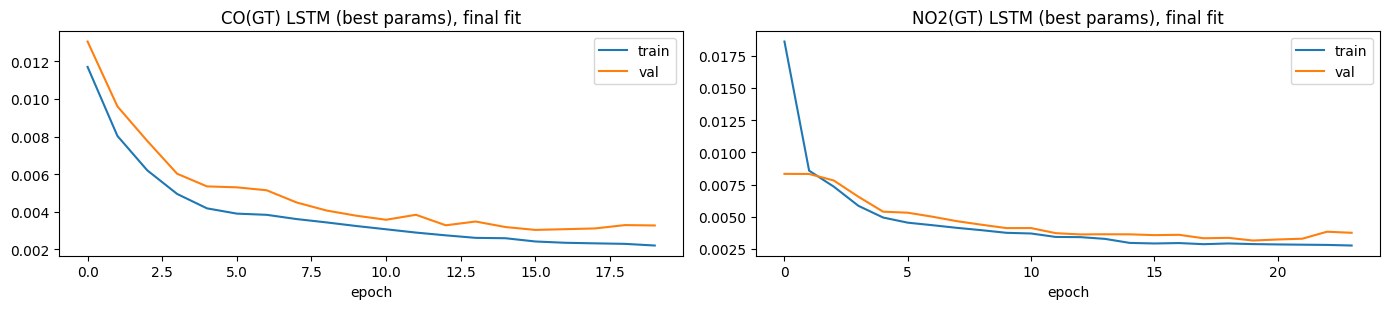

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.2))
for ax, t in zip(axes, TARGETS):
    hist = lstm_search[t].best_estimator_.history_
    ax.plot(hist["loss"], label="train"); ax.plot(hist["val_loss"], label="val")
    ax.set_title(f"{t} LSTM (best params), final fit"); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.show()

In [56]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [57]:
def mape(y_true, y_pred, eps=1e-6):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return np.mean(np.abs((y_true - y_pred) / np.maximum(np.abs(y_true), eps))) * 100

In [58]:
results = []
for t in TARGETS:
    p = predictions[t].dropna()
    for m in p.columns.drop("actual"):
        results.append({"Target": t, "Model": m,"MAE": mean_absolute_error(p["actual"], p[m]),
                        "RMSE": np.sqrt(mean_squared_error(p["actual"], p[m])),
                        "MAPE (%)": mape(p["actual"], p[m])})
results = pd.DataFrame(results).sort_values(["Target", "RMSE"]).reset_index(drop=True)
results

,Target,Model,MAE,RMSE,MAPE (%)
0,CO(GT),SARIMA,0.399579,0.596945,34.398009
1,CO(GT),Ridge regression,0.458583,0.656803,39.638337
2,CO(GT),LSTM,0.481791,0.664536,47.592644
3,CO(GT),Persistence (t-1),0.496598,0.785468,31.251306
4,CO(GT),Seasonal naive (t-24),0.856317,1.264608,71.953197
5,NO2(GT),SARIMA,14.718585,19.784467,11.291618
6,NO2(GT),Ridge regression,16.657365,22.093322,13.706402
7,NO2(GT),LSTM,18.858338,25.426615,14.101151
8,NO2(GT),Persistence (t-1),19.464209,26.303578,14.959533
9,NO2(GT),Seasonal naive (t-24),34.620459,46.355299,28.069623


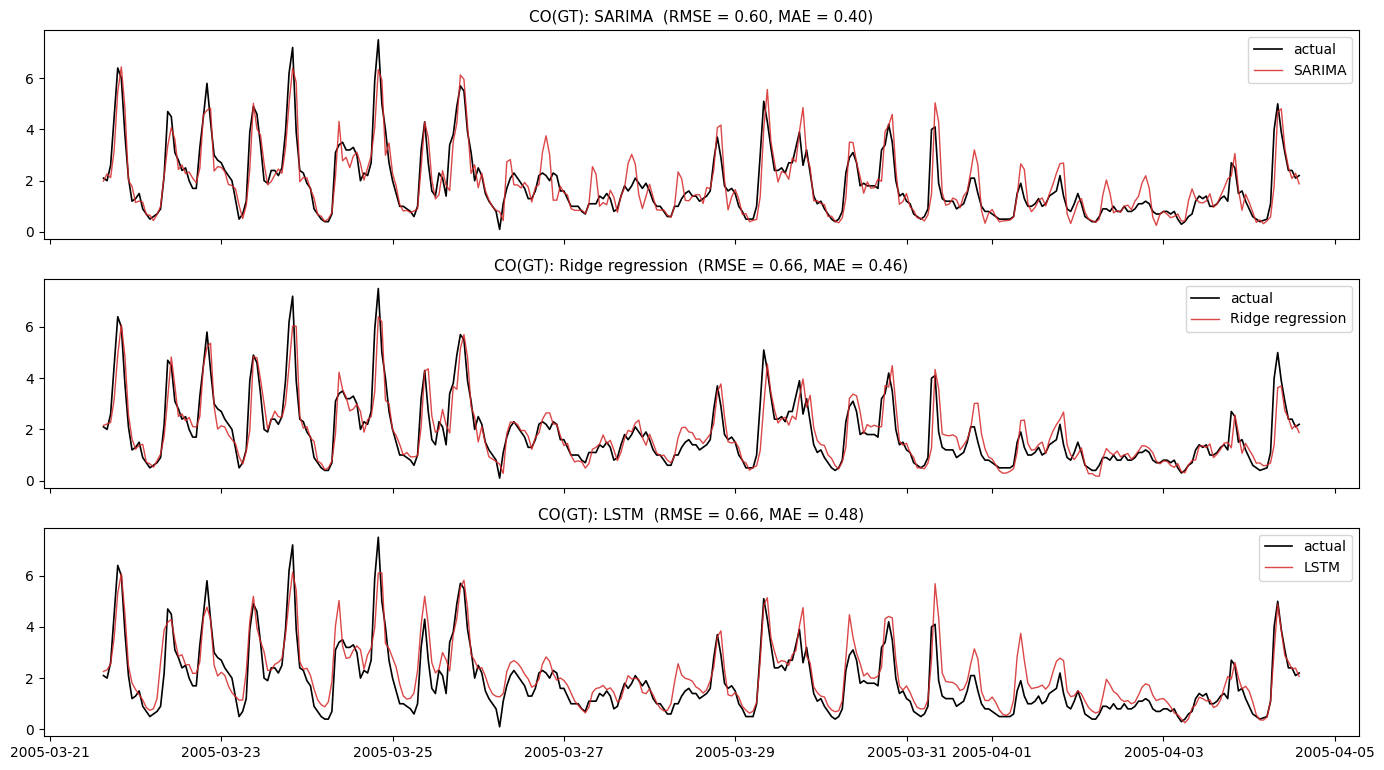

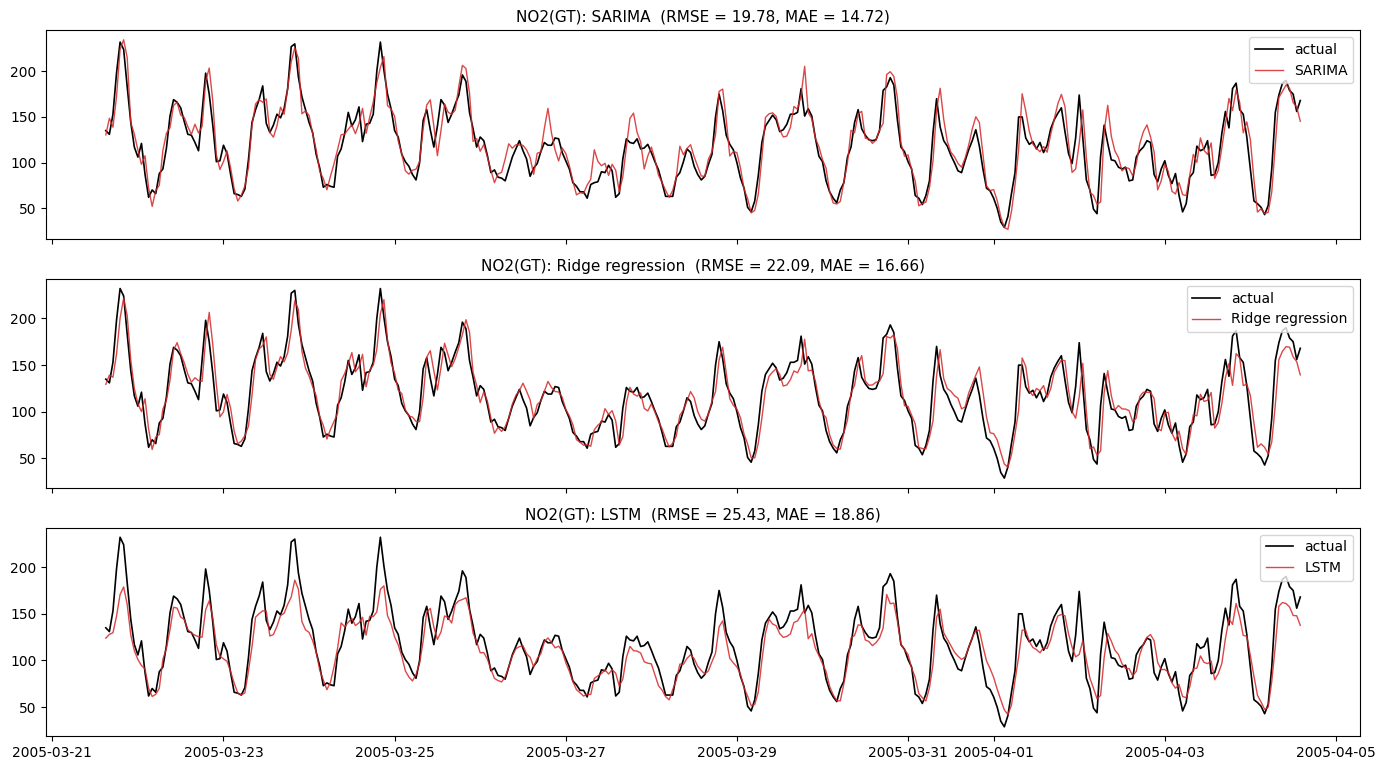

In [64]:
show = ["SARIMA", "Ridge regression", "LSTM"]
for t in TARGETS:
    # Get the best performing model's name dynamically for target t
    best_model = results[results.Target == t].Model.iloc[0]
    models = list(dict.fromkeys(show + [best_model]))
    p = predictions[t].iloc[-24 * 14:]
    fig, axes = plt.subplots(len(models), 1, figsize=(14, 2.6 * len(models)), sharex=True)
    for ax, m in zip(axes, models):
        r = results[(results.Target == t) & (results.Model == m)].iloc[0]
        ax.plot(p["actual"], color="black", lw=1.2, label="actual")
        ax.plot(p[m], color="tab:red", lw=1, alpha=0.85, label=m)
        ax.set_title(f"{t}: {m}  (RMSE = {r.RMSE:.2f}, MAE = {r.MAE:.2f})", fontsize=11)
        ax.legend(loc="upper right")
    plt.tight_layout(); plt.show()

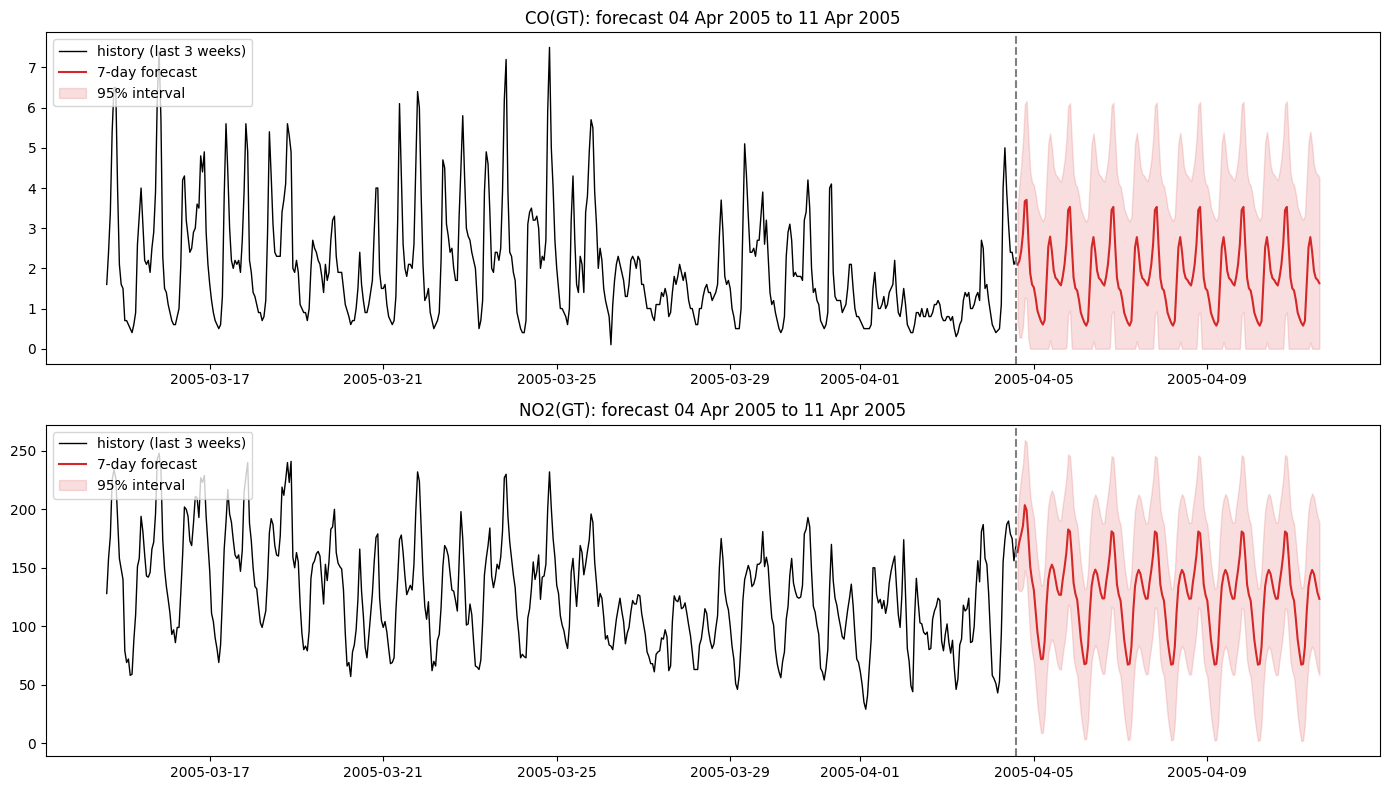

CO(GT)       NO2(GT)        
             mean   max    mean     max
Mon 04 Apr   2.57  3.71  174.43  203.59
Tue 05 Apr   1.83  3.53  130.34  182.80
Wed 06 Apr   1.81  3.53  126.74  181.16
Thu 07 Apr   1.81  3.53  126.48  181.06
Fri 08 Apr   1.81  3.53  126.46  181.05
Sat 09 Apr   1.81  3.53  126.46  181.05
Sun 10 Apr   1.81  3.53  126.46  181.05
Mon 11 Apr   1.50  2.78  112.16  148.17

In [65]:
HORIZON = 24*7
future = {}
fig, axes = plt.subplots(2, 1, figsize=(14, 8))
for ax, t in zip(axes, TARGETS):
    fc = sarima_results[t].get_forecast(steps=HORIZON)
    mean, ci = fc.predicted_mean.clip(lower=0), fc.conf_int(alpha=0.05).clip(lower=0)
    future[t] = pd.DataFrame({"forecast": mean, "lower95": ci.iloc[:, 0], "upper95": ci.iloc[:, 1]})
    hist = dfh[t].iloc[-24 * 21:]
    ax.plot(hist, color="black", lw=1, label="history (last 3 weeks)")
    ax.plot(mean, color="tab:red", lw=1.5, label="7-day forecast")
    ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], color="tab:red", alpha=0.15, label="95% interval")
    ax.axvline(dfh.index[-1], color="gray", ls="--")
    ax.set_title(f"{t}: forecast {mean.index[0]:%d %b %Y} to {mean.index[-1]:%d %b %Y}"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

daily_fc = pd.concat({t: future[t]["forecast"].resample("D").agg(["mean", "max"]) for t in TARGETS}, axis=1)
daily_fc.index = daily_fc.index.strftime("%a %d %b")
daily_fc.round(2)